# SegFormer-B0 baseline: fine-tune, predict, and evaluate

Run cells in order using the **Python (SUIM SegFormer)** kernel.
The default **MODE = 'train'** fine-tunes NVIDIA's ImageNet-pretrained MiT-B0
encoder and a new segmentation head on our existing cleaned SUIM training data.
This notebook reads the cleaned data; it does not clean the original dataset.
**MODE = 'checkpoint'** evaluates a SUIM checkpoint saved by this notebook.

There is no pretrained-only SUIM evaluation mode: the downloaded ImageNet
checkpoint has not learned the SUIM labels. Training must finish, or a compatible
SUIM checkpoint must be loaded, before TEST prediction is allowed.

For comparison with our U-Net notebook, this uses the same five independent
foreground channels in order: **RO, FV, HD, RI, WR**, binary cross-entropy,
320 x 240 inputs, and prediction threshold > 0.5. Water, plants, and sea-floor
have all-zero foreground targets. We use custom BCEWithLogitsLoss instead of
SegFormer's default multiclass cross-entropy loss. This preserves U-Net's
five-channel task; it is not an eight-class softmax experiment.

The original TEST split is reserved for final reporting. Validation loss chooses
the checkpoint. The authors' released U-Net score is a reference; a controlled
architecture comparison also requires training U-Net on our split and documenting
pretraining, optimizer, and framework differences.

## Environment

Use a separate Python 3.12 environment. From the project root in PowerShell:

~~~powershell
python -m venv .venv-segformer
.\.venv-segformer\Scripts\python.exe -m pip install torch==2.8.0 --index-url https://download.pytorch.org/whl/cu126
.\.venv-segformer\Scripts\python.exe -m pip install -r notebooks/requirements-segformer.txt
.\.venv-segformer\Scripts\python.exe -m ipykernel install --sys-prefix --name suim-segformer --display-name "Python (SUIM SegFormer)"
~~~

Select **.venv-segformer/Scripts/python.exe** as the notebook kernel in VS Code.
The CUDA command above supports our Windows NVIDIA setup; unlike the current
TensorFlow environment, PyTorch supports CUDA on native Windows.
For a CPU-only installation replace the torch index with
https://download.pytorch.org/whl/cpu. Other machines should use the appropriate
[official PyTorch build](https://pytorch.org/get-started/locally/).

The first training run downloads the pinned NVIDIA encoder into
.cache/huggingface/ in this project. Checkpoint evaluation loads the saved model
locally and does not need another encoder download.

In [1]:
import hashlib
import json
import math
import os
from pathlib import Path
import random
import time

os.environ.setdefault('HF_HUB_DISABLE_XET', '1')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import affine_transform, binary_dilation
from IPython.display import display
from tqdm.auto import tqdm
try:
    import torch
    from torch import nn
    import torch.nn.functional as F
    from torch.utils.data import Dataset, DataLoader
    import transformers
    from transformers import SegformerConfig, SegformerModel, SegformerForSemanticSegmentation
except ImportError as error:
    raise ImportError('Select the SegFormer kernel and install notebooks/requirements-segformer.txt.') from error

print('PyTorch:', torch.__version__, '| Transformers:', transformers.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

c:\Users\darre\OneDrive\Desktop\SUIM\.venv-segformer\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.8.0+cu126 | Transformers: 4.57.6
CUDA available: True
GPU: NVIDIA GeForce RTX 3070 Laptop GPU


## Configuration

**MODE = 'train' starts the full configured fine-tuning run when its cell is run.**
Use MODE = 'checkpoint' to evaluate the saved best SUIM weights instead.
The default training data is cleaned_suim/train_val/. Run the separate cleaning
script first if that directory is missing.

The existing U-Net split is checked by image SHA-256 and reused. If its CSV is
unavailable, the identical grouped, seeded U-Net algorithm recreates the split.
An existing split with missing images, changed image bytes, or leakage is refused.

Keep MAX_TEST_IMAGES = None for all 110 TEST images. A smaller value is a partial
smoke run and is marked in reports. The notebook always overwrites this model's
own fixed output folder and replaces its previous masks, including stale masks
from larger runs. Other models' outputs are untouched.

The image normalization below comes from the pinned NVIDIA encoder's processor
configuration. Training geometry matches our U-Net notebook: initial nearest
resizing, shared affine parameters, linear image interpolation, nearest mask
interpolation, and nearest edge fill. TEST image resizing is bicubic.

In [2]:
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'train_val/images').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Set ROOT to the SUIM project containing train_val/ and TEST/.')
ROOT = ROOT.resolve()
MODE = 'train'  # 'train' fine-tunes ImageNet weights; 'checkpoint' evaluates SUIM weights.
TRAIN_DIR = ROOT / 'cleaned_suim/train_val'
TEST_DIR = ROOT / 'TEST'
SPLIT_PATH = ROOT / 'data/test/output/unet/split.csv'
OUTPUT_DIR = ROOT / 'data/test/output/segformer_b0'
CKPT_DIR = ROOT / 'ckpt/segformer_b0'
CUSTOM_WEIGHTS = CKPT_DIR / 'best.pt'
MODEL_ID = 'nvidia/mit-b0'
MODEL_REVISION = '80983a413c30d36a39c20203974ae7807835e2b4'
MODEL_CACHE = ROOT / '.cache/huggingface'

WIDTH, HEIGHT = 320, 240
BATCH_SIZE = 2
INFERENCE_BATCH_SIZE = 1
EPOCHS = 50
LEARNING_RATE = 6e-5
WEIGHT_DECAY = 0.01
VALIDATION_FRACTION = 0.2
SEED = 42
PREDICTION_THRESHOLD = 0.5
MAX_TEST_IMAGES = None
USE_AUGMENTATION = True
USE_AMP = True
DEVICE_NAME = 'auto'  # 'auto', 'cuda', or 'cpu'
CLASSES = ['RO', 'FV', 'HD', 'RI', 'WR']
IMAGE_MEAN = [0.485, 0.456, 0.406]
IMAGE_STD = [0.229, 0.224, 0.225]
AUGMENTATION = dict(rotation_range=0.2, width_shift_range=0.05,
                    height_shift_range=0.05, shear_range=0.05, zoom_range=0.05,
                    horizontal_flip=True, fill_mode='nearest')

if MODE not in {'train', 'checkpoint'}:
    raise ValueError('Use train or checkpoint. ImageNet weights alone cannot evaluate SUIM.')
if not (TRAIN_DIR / 'images').is_dir() or not (TRAIN_DIR / 'masks').is_dir():
    raise FileNotFoundError('Create cleaned_suim with scripts/clean_dataset.py before training/evaluation.')
if WIDTH < 32 or HEIGHT < 32 or WIDTH % 16 or HEIGHT % 16:
    raise ValueError('WIDTH and HEIGHT must be multiples of 16 and at least 32.')
if min(BATCH_SIZE, INFERENCE_BATCH_SIZE, EPOCHS) < 1:
    raise ValueError('Batch sizes and EPOCHS must be positive.')
if not 0 < VALIDATION_FRACTION < 1 or not 0 < PREDICTION_THRESHOLD < 1:
    raise ValueError('Validation fraction and prediction threshold must be between 0 and 1.')
if MAX_TEST_IMAGES is not None and (not isinstance(MAX_TEST_IMAGES, int) or MAX_TEST_IMAGES < 1):
    raise ValueError('MAX_TEST_IMAGES must be None or a positive integer.')
if DEVICE_NAME not in {'auto', 'cuda', 'cpu'}:
    raise ValueError('DEVICE_NAME must be auto, cuda, or cpu.')
if DEVICE_NAME == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('CUDA was requested but is not available in this kernel.')
DEVICE = torch.device('cuda' if DEVICE_NAME == 'auto' and torch.cuda.is_available()
                      else 'cpu' if DEVICE_NAME == 'auto' else DEVICE_NAME)
AMP_ENABLED = USE_AMP and DEVICE.type == 'cuda'
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
print('Mode:', MODE, '| Device:', DEVICE, '| Mixed-precision training:', AMP_ENABLED)
print('Training:', TRAIN_DIR, '| Test:', TEST_DIR)
print('Output directory (overwritten):', OUTPUT_DIR)

Mode: train | Device: cuda | Mixed-precision training: True
Training: C:\Users\darre\OneDrive\Desktop\SUIM\cleaned_suim\train_val | Test: C:\Users\darre\OneDrive\Desktop\SUIM\TEST
Output directory (overwritten): C:\Users\darre\OneDrive\Desktop\SUIM\data\test\output\segformer_b0


In [3]:
def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as file:
        for block in iter(lambda: file.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def index_files(folder, extensions):
    files = {}
    for path in sorted(Path(folder).iterdir()):
        if path.is_file() and path.suffix.lower() in extensions:
            if path.stem in files:
                raise ValueError(f'Ambiguous stem: {folder / path.stem}')
            files[path.stem] = path
    return files


def getRobotFishHumanReefWrecks(mask):
    colors = np.array([(1, 0, 0), (1, 1, 0), (0, 0, 1), (1, 0, 1), (0, 1, 1)])
    return np.all(np.asarray(mask)[..., None, :] == colors, axis=-1).astype(np.float32)


def processSUIMDataRFHW(image, mask):
    return np.asarray(image, dtype=np.float32) / 255.0, getRobotFishHumanReefWrecks(np.asarray(mask) > 127.5)


def grouped_split(images, validation_fraction, seed):
    groups = {}
    for stem, path in images.items():
        groups.setdefault(file_sha256(path), []).append(stem)
    if len(groups) < 2:
        raise ValueError('At least two unique image groups are needed for a split')
    hashes = np.array(sorted(groups))
    np.random.default_rng(seed).shuffle(hashes)
    n_validation = min(len(hashes) - 1, max(1, round(len(hashes) * validation_fraction)))
    validation_hashes = set(hashes[:n_validation])
    rows = [{'stem': stem, 'image_sha256': digest,
             'partition': 'validation' if digest in validation_hashes else 'train'}
            for digest, stems in sorted(groups.items()) for stem in stems]
    return pd.DataFrame(rows).sort_values('stem').reset_index(drop=True)


def load_or_create_split(images, path, validation_fraction, seed):
    if not Path(path).is_file():
        return grouped_split(images, validation_fraction, seed), 'regenerated U-Net grouped split'
    table = pd.read_csv(path, dtype={'stem': str, 'image_sha256': str, 'partition': str})
    required = ['stem', 'image_sha256', 'partition']
    if not set(required).issubset(table.columns):
        raise ValueError('Saved split must contain stem, image_sha256, and partition.')
    table = table[required].copy()
    if table.isna().any().any() or table.stem.duplicated().any() or set(table.stem) != set(images):
        raise ValueError('Saved split must contain every training image exactly once.')
    if set(table.partition) != {'train', 'validation'}:
        raise ValueError('Saved split must contain only nonempty train and validation partitions.')
    actual_hashes = {stem: file_sha256(path) for stem, path in images.items()}
    if not table.image_sha256.equals(table.stem.map(actual_hashes)):
        raise ValueError('Saved split image hashes do not match the current dataset.')
    if table.groupby('image_sha256').partition.nunique().max() != 1:
        raise ValueError('Saved split leaks duplicate images across training and validation.')
    return table.sort_values('stem').reset_index(drop=True), str(Path(path).resolve())

In [4]:
train_images = index_files(TRAIN_DIR / 'images', {'.jpg', '.jpeg', '.png'})
train_masks = index_files(TRAIN_DIR / 'masks', {'.bmp', '.png'})
if not train_images or train_images.keys() != train_masks.keys():
    raise ValueError('Cleaned training images and RGB masks must pair exactly by stem.')
split, split_source = load_or_create_split(train_images, SPLIT_PATH, VALIDATION_FRACTION, SEED)
train_stems = split.loc[split.partition == 'train', 'stem'].tolist()
validation_stems = split.loc[split.partition == 'validation', 'stem'].tolist()

test_images = index_files(TEST_DIR / 'images', {'.jpg', '.jpeg', '.png'})
if not test_images:
    raise ValueError('No TEST images found.')
ground_truth = {symbol: index_files(TEST_DIR / 'masks' / symbol, {'.bmp', '.png'}) for symbol in CLASSES}
for symbol, masks in ground_truth.items():
    if masks.keys() != test_images.keys():
        raise ValueError(f'TEST {symbol} masks must pair exactly with TEST images.')
selected_test_stems = sorted(test_images)
if MAX_TEST_IMAGES is not None:
    selected_test_stems = selected_test_stems[:MAX_TEST_IMAGES]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
split.to_csv(OUTPUT_DIR / 'split.csv', index=False, lineterminator='\n')
SPLIT_SHA256 = file_sha256(OUTPUT_DIR / 'split.csv')
print(f'{len(train_stems)} training + {len(validation_stems)} validation pairs')
print('Split source:', split_source)
print(f'{len(selected_test_stems)}/{len(test_images)} TEST images selected')

1220 training + 305 validation pairs
Split source: C:\Users\darre\OneDrive\Desktop\SUIM\data\test\output\unet\split.csv
110/110 TEST images selected


## Paired augmentation and PyTorch loader

The affine distribution and transform order match our U-Net ImageDataGenerator
settings. A private NumPy RandomState uses the same seed formula, so the affine
choice for a given training sample and epoch matches U-Net without importing
TensorFlow. Images use linear interpolation during augmentation; masks use
nearest-neighbor interpolation. Both use the same transform and horizontal flip.
There is no validation or TEST augmentation. Normalization follows ImageNet
pretraining and differs from U-Net's simple division by 255.

Mask RGB channels are thresholded at > 127.5, following the upstream SUIM policy
for noncanonical colors. Optional class-ID masks from the cleaning script are
not used. Conflicting duplicate annotations stay together in one partition.

In [5]:
def paired_augmentation(image, mask, seed):
    rng = np.random.RandomState(seed)
    height, width = image.shape[:2]
    theta = np.deg2rad(rng.uniform(-AUGMENTATION['rotation_range'], AUGMENTATION['rotation_range']))
    tx = rng.uniform(-AUGMENTATION['height_shift_range'], AUGMENTATION['height_shift_range']) * height
    ty = rng.uniform(-AUGMENTATION['width_shift_range'], AUGMENTATION['width_shift_range']) * width
    shear = np.deg2rad(rng.uniform(-AUGMENTATION['shear_range'], AUGMENTATION['shear_range']))
    zx, zy = rng.uniform(1 - AUGMENTATION['zoom_range'], 1 + AUGMENTATION['zoom_range'], 2)
    flip = rng.random_sample() < 0.5 and AUGMENTATION['horizontal_flip']
    rotation = np.array([[np.cos(theta), -np.sin(theta), 0],
                         [np.sin(theta), np.cos(theta), 0], [0, 0, 1]])
    shift = np.array([[1, 0, tx], [0, 1, ty], [0, 0, 1]])
    skew = np.array([[1, -np.sin(shear), 0], [0, np.cos(shear), 0], [0, 0, 1]])
    zoom = np.diag([zx, zy, 1])
    center = np.array([[1, 0, height / 2 - 0.5],
                       [0, 1, width / 2 - 0.5], [0, 0, 1]])
    reset = np.array([[1, 0, -height / 2 + 0.5],
                      [0, 1, -width / 2 + 0.5], [0, 0, 1]])
    matrix = center @ rotation @ shift @ skew @ zoom @ reset
    matrix = matrix[np.ix_([1, 0, 2], [1, 0, 2])]

    def apply(array, order):
        result = np.stack([affine_transform(array[..., channel], matrix[:2, :2],
                            matrix[:2, 2], order=order, mode=AUGMENTATION['fill_mode'])
                           for channel in range(array.shape[-1])], axis=-1)
        return result[:, ::-1] if flip else result

    return apply(image, 1), apply(mask, 0)


def normalize_image(image):
    image = np.asarray(image, dtype=np.float32) / 255.0
    mean = np.asarray(IMAGE_MEAN, dtype=np.float32)
    std = np.asarray(IMAGE_STD, dtype=np.float32)
    return torch.from_numpy(np.ascontiguousarray(((image - mean) / std).transpose(2, 0, 1)))


class SUIMDataset(Dataset):
    def __init__(self, stems, images, masks, size, *, augment=False):
        if not stems:
            raise ValueError('Dataset must contain at least one image.')
        self.stems, self.images, self.masks = tuple(stems), images, masks
        self.size, self.augment, self.epoch = size, augment, 0

    def __len__(self):
        return len(self.stems)

    def __getitem__(self, index):
        stem = self.stems[index]
        with Image.open(self.images[stem]) as source:
            image = source.convert('RGB')
        with Image.open(self.masks[stem]) as source:
            mask = source.convert('RGB')
        if image.size != mask.size:
            raise ValueError(f'{stem}: cleaned image and mask dimensions must match.')
        image = np.asarray(image.resize(self.size, Image.Resampling.NEAREST), dtype=np.float32)
        mask = np.asarray(mask.resize(self.size, Image.Resampling.NEAREST), dtype=np.float32)
        if self.augment:
            image, mask = paired_augmentation(image, mask, SEED + self.epoch * len(self.stems) + index)
        target = getRobotFishHumanReefWrecks(mask > 127.5)
        target = torch.from_numpy(np.ascontiguousarray(target.transpose(2, 0, 1)))
        return normalize_image(image), target


training_data = SUIMDataset(train_stems, train_images, train_masks, (WIDTH, HEIGHT),
                            augment=USE_AUGMENTATION)
validation_data = SUIMDataset(validation_stems, train_images, train_masks, (WIDTH, HEIGHT))
generator = torch.Generator().manual_seed(SEED)
training_loader = DataLoader(training_data, batch_size=BATCH_SIZE, shuffle=True, generator=generator,
                             num_workers=0, pin_memory=DEVICE.type == 'cuda')
validation_loader = DataLoader(validation_data, batch_size=BATCH_SIZE, shuffle=False,
                               num_workers=0, pin_memory=DEVICE.type == 'cuda')
print('Batches per epoch:', len(training_loader), '| Validation batches:', len(validation_loader))

Batches per epoch: 610 | Validation batches: 153


## Model initialization and SUIM checkpoints

Training loads the pinned ImageNet encoder, checks that all encoder weights were
loaded, and copies them strictly into a SegFormer-B0 model with a new five-output
head. The unused ImageNet classifier may appear in the loading log.

The SUIM checkpoint includes the complete model configuration, weights, class
order, image normalization, resolution, mask policy, and training-split hash.
Checkpoint mode validates those settings and loads locally with weights_only=True.
It evaluates the checkpoint; it does not resume an optimizer or training schedule.

In [6]:
TARGET_POLICY = 'RGB channels >127.5; five independent foreground targets; BCEWithLogitsLoss'


def checkpoint_protocol():
    return {'model': 'segformer_b0', 'classes': CLASSES, 'image_size_width_height': [WIDTH, HEIGHT],
            'image_mean': IMAGE_MEAN, 'image_std': IMAGE_STD, 'target_policy': TARGET_POLICY,
            'split_sha256': SPLIT_SHA256}


def load_suim_checkpoint(path, expected_protocol):
    payload = torch.load(path, map_location='cpu', weights_only=True)
    if not isinstance(payload, dict) or not {'state_dict', 'config', 'metadata'}.issubset(payload):
        raise ValueError('Expected a complete SUIM SegFormer checkpoint saved by this notebook.')
    for key, expected in expected_protocol.items():
        if payload['metadata'].get(key) != expected:
            raise ValueError(f'Checkpoint protocol mismatch: {key}')
    config = SegformerConfig(**payload['config'])
    if config.num_labels != len(expected_protocol['classes']):
        raise ValueError('Checkpoint output channel count differs from the SUIM task.')
    if [config.id2label[i] for i in range(config.num_labels)] != expected_protocol['classes']:
        raise ValueError('Checkpoint configuration class order differs from the SUIM task.')
    restored = SegformerForSemanticSegmentation(config)
    restored.load_state_dict(payload['state_dict'], strict=True)
    return restored, payload['metadata']


def save_suim_checkpoint(model, path, metadata):
    payload = {'state_dict': {name: value.detach().cpu() for name, value in model.state_dict().items()},
               'config': model.config.to_dict(), 'metadata': metadata}
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix('.tmp')
    torch.save(payload, temporary)
    temporary.replace(path)


def full_resolution_logits(model, images, size):
    logits = model(pixel_values=images).logits
    return F.interpolate(logits, size=size, mode='bilinear', align_corners=False)

In [7]:
BEST_WEIGHTS = CKPT_DIR / 'best.pt'
WEIGHTS_PATH = None
CHECKPOINT_METADATA = None
READY_FOR_EVALUATION = False
if MODE == 'train':
    encoder, loading_info = SegformerModel.from_pretrained(
        MODEL_ID, revision=MODEL_REVISION, cache_dir=MODEL_CACHE,
        output_loading_info=True)
    if loading_info['missing_keys'] or loading_info.get('mismatched_keys') or loading_info.get('error_msgs'):
        raise RuntimeError(f'Incomplete ImageNet encoder loading: {loading_info}')
    config = encoder.config
    config.num_labels = len(CLASSES)
    config.id2label = dict(enumerate(CLASSES))
    config.label2id = {name: index for index, name in enumerate(CLASSES)}
    config.decoder_hidden_size = 256
    model = SegformerForSemanticSegmentation(config)
    model.segformer.load_state_dict(encoder.state_dict(), strict=True)
    del encoder
    print('Loaded ImageNet encoder; initialized a new SUIM head. Fine-tuning is required.')
else:
    if not CUSTOM_WEIGHTS.is_file():
        raise FileNotFoundError(f'No SUIM checkpoint at {CUSTOM_WEIGHTS}. Train first or set CUSTOM_WEIGHTS.')
    model, CHECKPOINT_METADATA = load_suim_checkpoint(CUSTOM_WEIGHTS, checkpoint_protocol())
    WEIGHTS_PATH = CUSTOM_WEIGHTS
    READY_FOR_EVALUATION = True
    print('Loaded SUIM checkpoint:', WEIGHTS_PATH)
model = model.to(DEVICE)
print('Parameters:', f'{sum(parameter.numel() for parameter in model.parameters()):,}')
print('Model device:', next(model.parameters()).device)

Loaded ImageNet encoder; initialized a new SUIM head. Fine-tuning is required.
Parameters: 3,715,429
Model device: cuda:0


## Fine-tune (only in train mode)

Each epoch visits the training partition once. AdamW updates the complete model
at 6e-5 with weight decay 0.01. This optimizer recipe differs from U-Net's Adam
recipe; record that difference in the project report. The augmentation settings,
split, epoch count, and best-validation-loss checkpoint policy match our U-Net
workflow. CUDA mixed precision is enabled by default for training.

The checkpoint, history CSV, and loss plot reuse ckpt/segformer_b0/.
After the configured epochs, the best checkpoint from this run is reloaded
before TEST inference. An interrupted or failed training cell cannot produce
TEST scores from the untrained head.

Epoch 1/50: loss=0.32621, val_loss=0.20045


Epoch 2/50: loss=0.17161, val_loss=0.11526


Epoch 3/50: loss=0.14229, val_loss=0.11270


Epoch 4/50: loss=0.12563, val_loss=0.11043


Epoch 5/50: loss=0.11545, val_loss=0.10266


Epoch 6/50: loss=0.10620, val_loss=0.10326


... (40 outputs left out)

Epoch 47/50: loss=0.04843, val_loss=0.11999


Epoch 48/50: loss=0.04888, val_loss=0.12365


Epoch 49/50: loss=0.04312, val_loss=0.12261


Epoch 50/50: loss=0.05238, val_loss=0.12682


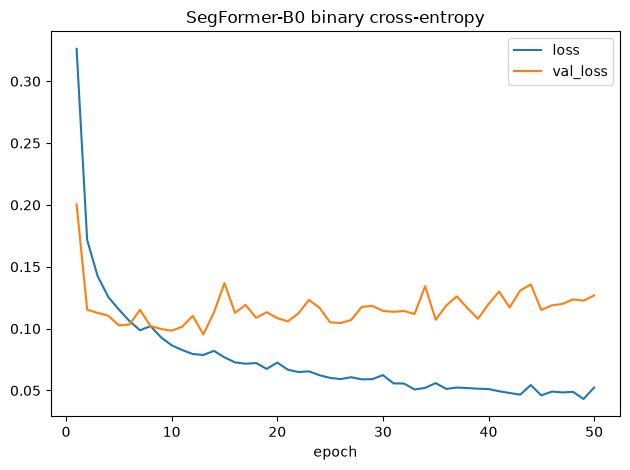

In [8]:
if MODE == 'train':
    READY_FOR_EVALUATION = False
    CKPT_DIR.mkdir(parents=True, exist_ok=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterion = nn.BCEWithLogitsLoss()
    scaler = torch.amp.GradScaler('cuda', enabled=AMP_ENABLED)
    history_rows = []
    best_val_loss = float('inf')
    best_written_this_run = False
    for epoch in range(EPOCHS):
        started = time.perf_counter()
        training_data.epoch = epoch
        model.train()
        train_total = 0.0
        for images, targets in tqdm(training_loader, desc=f'Epoch {epoch + 1}/{EPOCHS}', leave=False):
            images, targets = images.to(DEVICE), targets.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ENABLED):
                logits = full_resolution_logits(model, images, targets.shape[-2:])
                loss = criterion(logits, targets)
            if not torch.isfinite(loss):
                raise RuntimeError('Non-finite training loss; stop and inspect this run.')
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            train_total += loss.item() * images.shape[0]
        model.eval()
        validation_total = 0.0
        with torch.inference_mode():
            for images, targets in validation_loader:
                images, targets = images.to(DEVICE), targets.to(DEVICE)
                logits = full_resolution_logits(model, images, targets.shape[-2:])
                loss = criterion(logits, targets)
                if not torch.isfinite(loss):
                    raise RuntimeError('Non-finite validation loss; stop and inspect this run.')
                validation_total += loss.item() * images.shape[0]
        train_loss = train_total / len(training_data)
        val_loss = validation_total / len(validation_data)
        history_rows.append({'epoch': epoch + 1, 'loss': train_loss, 'val_loss': val_loss,
                             'seconds': time.perf_counter() - started})
        pd.DataFrame(history_rows).to_csv(CKPT_DIR / 'training_history.csv', index=False)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            metadata = {**checkpoint_protocol(), 'epoch': epoch + 1, 'val_loss': val_loss,
                        'encoder_id': MODEL_ID, 'encoder_revision': MODEL_REVISION,
                        'seed': SEED, 'learning_rate': LEARNING_RATE, 'weight_decay': WEIGHT_DECAY,
                        'use_augmentation': USE_AUGMENTATION, 'augmentation': AUGMENTATION,
                        'mixed_precision_training': AMP_ENABLED}
            save_suim_checkpoint(model, BEST_WEIGHTS, metadata)
            best_written_this_run = True
        print(f'Epoch {epoch + 1}/{EPOCHS}: loss={train_loss:.5f}, val_loss={val_loss:.5f}')
    if not best_written_this_run:
        raise RuntimeError('This run did not produce a valid checkpoint.')
    model, CHECKPOINT_METADATA = load_suim_checkpoint(BEST_WEIGHTS, checkpoint_protocol())
    model = model.to(DEVICE)
    WEIGHTS_PATH = BEST_WEIGHTS
    READY_FOR_EVALUATION = True
    history_table = pd.DataFrame(history_rows)
    history_table.plot(x='epoch', y=['loss', 'val_loss'], title='SegFormer-B0 binary cross-entropy')
    plt.tight_layout()
    plt.savefig(CKPT_DIR / 'training_loss.png', dpi=140)
    plt.show()
else:
    print('Training skipped; evaluating the loaded SUIM checkpoint.')

## TEST prediction

Only a trained SUIM checkpoint is evaluated. Inputs use the same bicubic TEST
resizing as U-Net, followed by ImageNet normalization. SegFormer predicts
lower-resolution logits; they are bilinearly resized to the configured image
size before sigmoid and > 0.5 thresholding. This saves one binary BMP per class
per TEST image under data/test/output/segformer_b0/{RO,FV,HD,RI,WR}/.
Inference uses float32; training mixed precision does not change this setting.

In [9]:
def predict_and_save(model, image_paths, stems, output_dir, size, batch_size, threshold, device):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    for symbol in CLASSES:
        class_dir = output_dir / symbol
        class_dir.mkdir(exist_ok=True)
        for previous in class_dir.iterdir():
            if previous.is_file() and previous.suffix.lower() in {'.bmp', '.png'}:
                previous.unlink()
    model.eval()
    with torch.inference_mode():
        for start in range(0, len(stems), batch_size):
            selected = stems[start:start + batch_size]
            images = []
            for stem in selected:
                with Image.open(image_paths[stem]) as source:
                    image = source.convert('RGB').resize(size, Image.Resampling.BICUBIC)
                images.append(normalize_image(image))
            logits = full_resolution_logits(model, torch.stack(images).to(device), (size[1], size[0]))
            probabilities = logits.sigmoid()
            if probabilities.shape != (len(selected), len(CLASSES), size[1], size[0]):
                raise ValueError(f'Unexpected model output shape: {probabilities.shape}')
            if not torch.isfinite(probabilities).all():
                raise ValueError('Non-finite TEST predictions.')
            binary = (probabilities > threshold).cpu().numpy()
            for index, stem in enumerate(selected):
                for channel, symbol in enumerate(CLASSES):
                    Image.fromarray(binary[index, channel].astype(np.uint8) * 255).save(
                        output_dir / symbol / f'{stem}.bmp')
            if start == 0 or start + batch_size >= len(stems) or (start + batch_size) % 20 == 0:
                print(f'Predicted {min(start + batch_size, len(stems))}/{len(stems)} images')
    return output_dir

In [10]:
if not READY_FOR_EVALUATION or WEIGHTS_PATH is None:
    raise RuntimeError('Complete fine-tuning or load a SUIM checkpoint before TEST prediction.')
PREDICTION_DIR = predict_and_save(model, test_images, selected_test_stems, OUTPUT_DIR,
                                  (WIDTH, HEIGHT), INFERENCE_BATCH_SIZE, PREDICTION_THRESHOLD, DEVICE)
pd.DataFrame({'stem': selected_test_stems,
              'image_path': [str(test_images[stem]) for stem in selected_test_stems]}).to_csv(
                  OUTPUT_DIR / 'test_images.csv', index=False)

Predicted 1/110 images
Predicted 20/110 images
Predicted 40/110 images
Predicted 60/110 images
Predicted 80/110 images
Predicted 100/110 images
Predicted 110/110 images


## Boundary F-score and IoU: identical to our U-Net evaluator

The functions in the next cell are copied unchanged from 02_unet_baseline.ipynb.
This is boundary F-score, not pixel Dice/F1. Tolerance is ceil(0.008 times the image
diagonal). The evaluator resizes binary masks with bicubic interpolation and
thresholds at >= 0.5, matching the upstream evaluation policy.

Each class is scored over TEST images where that class is present in the ground
truth. False positives on absent-class images are recorded but excluded from that
class's mean, following upstream. The overall result is a macro mean of the five
class means, not global confusion-matrix IoU or eight-class mIoU. Filename
inventories must match exactly. Do not tune model settings using TEST scores.

In [11]:
def disk(radius):
    y, x = np.ogrid[-radius:radius + 1, -radius:radius + 1]
    return x * x + y * y <= radius * radius


def seg2bmap(seg):
    seg = np.asarray(seg, dtype=bool)
    if seg.ndim != 2:
        raise ValueError('Expected a two-dimensional binary mask')
    e, s, se = np.zeros_like(seg), np.zeros_like(seg), np.zeros_like(seg)
    e[:, :-1] = seg[:, 1:]
    s[:-1, :] = seg[1:, :]
    se[:-1, :-1] = seg[1:, 1:]
    boundary = seg ^ e | seg ^ s | seg ^ se
    boundary[-1, :] = seg[-1, :] ^ e[-1, :]
    boundary[:, -1] = seg[:, -1] ^ s[:, -1]
    boundary[-1, -1] = False
    return boundary


def db_eval_boundary(foreground_mask, gt_mask, bound_th=0.008):
    """
    Arguments:
        foreground_mask (ndarray): binary segmentation image.
        gt_mask         (ndarray): binary annotated image.
    Returns:
        P (float): boundaries precision
        R (float): boundaries recall
        F (float): boundaries F-measure
    """
    assert np.atleast_3d(foreground_mask).shape[2] == 1
    bound_pix = bound_th if bound_th >= 1 else \
                np.ceil(bound_th*np.linalg.norm(foreground_mask.shape))

    # Get the pixel boundaries of both masks
    fg_boundary = seg2bmap(foreground_mask);
    gt_boundary = seg2bmap(gt_mask);

    fg_dil = binary_dilation(fg_boundary,disk(int(bound_pix)))
    gt_dil = binary_dilation(gt_boundary,disk(int(bound_pix)))

    # Get the intersection
    gt_match = gt_boundary * fg_dil
    fg_match = fg_boundary * gt_dil

    # Area of the intersection
    n_fg     = np.sum(fg_boundary)
    n_gt     = np.sum(gt_boundary)

    #% Compute precision and recall
    if n_fg == 0 and  n_gt > 0:
        precision = 1
        recall = 0
    elif n_fg > 0 and n_gt == 0:
        precision = 0
        recall = 1
    elif n_fg == 0  and n_gt == 0:
        precision = 1
        recall = 1
    else:
        precision = np.sum(fg_match)/float(n_fg)
        recall    = np.sum(gt_match)/float(n_gt)

    # Compute F measure
    if precision + recall == 0:
        F = 0
    else:
        F = 2*precision*recall/(precision+recall);

    return precision, recall, F


def IoU_bin(target, prediction):
    union = np.logical_or(target, prediction).sum()
    return float(np.logical_and(target, prediction).sum() / union) if union else 1.0


def read_and_bin(path, size):
    with Image.open(path) as source:
        image = source.convert('L').resize(size, Image.Resampling.BICUBIC)
    return np.asarray(image, dtype=np.float32) / 255.0 >= 0.5


def evaluate_predictions(prediction_dir, ground_truth, stems, size):
    rows = []
    for symbol in CLASSES:
        predictions = index_files(prediction_dir / symbol, {'.bmp', '.png'})
        if set(predictions) != set(stems):
            raise ValueError(f'{symbol}: prediction stems differ from the selected TEST list')
        for stem in stems:
            real = read_and_bin(ground_truth[symbol][stem], size)
            generated = read_and_bin(predictions[stem], size)
            present = bool(real.any())
            precision, recall, f1 = db_eval_boundary(generated, real) if present else (np.nan,) * 3
            rows.append({'stem': stem, 'class': symbol, 'ground_truth_present': present,
                         'ground_truth_pixels': int(real.sum()), 'predicted_pixels': int(generated.sum()),
                         'boundary_precision': precision, 'boundary_recall': recall,
                         'boundary_f': f1, 'iou': IoU_bin(real, generated) if present else np.nan})
    per_image = pd.DataFrame(rows)
    class_rows = []
    for symbol in CLASSES:
        subset = per_image.loc[per_image['class'] == symbol]
        class_rows.append({'class': symbol, 'scored_images': int(subset.ground_truth_present.sum()),
                           'skipped_empty_gt_images': int((~subset.ground_truth_present).sum()),
                           'boundary_f_pct': 100 * subset.boundary_f.mean(), 'iou_pct': 100 * subset.iou.mean()})
    return per_image, pd.DataFrame(class_rows)

In [12]:
per_image_metrics, class_metrics = evaluate_predictions(
    PREDICTION_DIR, ground_truth, selected_test_stems, (WIDTH, HEIGHT))
per_image_metrics.to_csv(OUTPUT_DIR / 'per_image_metrics.csv', index=False)
class_metrics.to_csv(OUTPUT_DIR / 'class_metrics.csv', index=False)
display(class_metrics.round(2))

def finite_or_none(value):
    return float(value) if np.isfinite(value) else None

summary = {
    'model': 'segformer_b0', 'mode': MODE, 'weights': str(WEIGHTS_PATH),
    'weights_sha256': file_sha256(WEIGHTS_PATH), 'checkpoint_metadata': CHECKPOINT_METADATA,
    'training_directory': str(TRAIN_DIR), 'test_directory': str(TEST_DIR),
    'train_pairs': len(train_stems), 'validation_pairs': len(validation_stems),
    'split_source': split_source, 'split_sha256': SPLIT_SHA256,
    'test_images_evaluated': len(selected_test_stems), 'test_images_available': len(test_images),
    'partial_test': len(selected_test_stems) != len(test_images),
    'classes': CLASSES, 'image_size_width_height': [WIDTH, HEIGHT], 'threshold': PREDICTION_THRESHOLD,
    'seed': SEED, 'epochs_requested': EPOCHS if MODE == 'train' else 0,
    'encoder_pretraining': 'ImageNet-1k; SUIM head initialized for this task',
    'image_mean': IMAGE_MEAN, 'image_std': IMAGE_STD,
    'macro_boundary_f_pct': finite_or_none(class_metrics.boundary_f_pct.mean()),
    'macro_iou_pct': finite_or_none(class_metrics.iou_pct.mean()),
    'metric_protocol': 'Per-image boundary F and binary IoU; skip empty GT per class; macro mean of class means',
    'training_protocol': 'U-Net grouped split and paired augmentation; AdamW; BCEWithLogitsLoss; best validation-loss checkpoint',
    'device': str(DEVICE), 'gpu': torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None,
    'inference_precision': 'float32', 'torch_version': str(torch.__version__),
    'transformers_version': transformers.__version__, 'numpy_version': np.__version__,
}
(OUTPUT_DIR / 'summary.json').write_text(
    json.dumps(summary, indent=2, allow_nan=False) + '\n', encoding='utf-8')
print('Macro boundary F (%):', summary['macro_boundary_f_pct'])
print('Macro IoU (%):', summary['macro_iou_pct'])
print('PARTIAL TEST RUN' if summary['partial_test'] else 'Full TEST inventory evaluated')
print('Saved predictions, split, and metrics under:', OUTPUT_DIR)

,class,scored_images,skipped_empty_gt_images,boundary_f_pct,iou_pct
0,RO,12,98,26.34,25.53
1,FV,66,44,57.57,57.49
2,HD,42,68,63.83,60.83
3,RI,58,52,36.80,57.25
4,WR,27,83,46.20,60.01


Macro boundary F (%): 46.15043423074023
Macro IoU (%): 52.219877515229584
Full TEST inventory evaluated
Saved predictions, split, and metrics under: C:\Users\darre\OneDrive\Desktop\SUIM\data\test\output\segformer_b0


## Inspect a prediction

The top row shows ground truth and the bottom row shows predictions. The metrics
above use all selected saved masks, not just this preview image. This notebook
does not benchmark inference FPS; compare speed only after defining a common
timing protocol for all models on the same hardware.

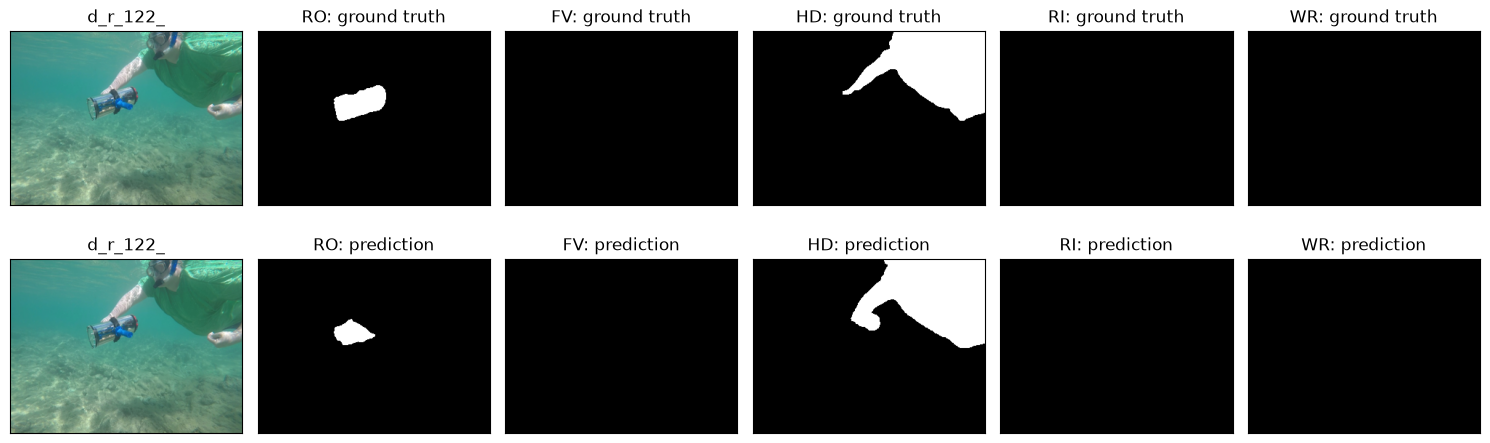

In [13]:
stem = selected_test_stems[0]
with Image.open(test_images[stem]) as source:
    image = source.convert('RGB').resize((WIDTH, HEIGHT), Image.Resampling.BICUBIC)
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for row in range(2):
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(stem)
for channel, symbol in enumerate(CLASSES, start=1):
    axes[0, channel].imshow(read_and_bin(ground_truth[symbol][stem], (WIDTH, HEIGHT)), cmap='gray', vmin=0, vmax=1)
    axes[0, channel].set_title(f'{symbol}: ground truth')
    axes[1, channel].imshow(read_and_bin(PREDICTION_DIR / symbol / f'{stem}.bmp', (WIDTH, HEIGHT)), cmap='gray', vmin=0, vmax=1)
    axes[1, channel].set_title(f'{symbol}: prediction')
for axis in axes.flat:
    axis.set_xticks([])
    axis.set_yticks([])
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'prediction_example.png', dpi=140)
plt.show()

## Sources and experiment differences

- [SegFormer paper](https://arxiv.org/abs/2105.15203)
- [Official NVIDIA implementation](https://github.com/NVlabs/SegFormer)
- [NVIDIA MiT-B0 encoder and weight-license information](https://huggingface.co/nvidia/mit-b0)
- [Hugging Face SegFormer API](https://huggingface.co/docs/transformers/model_doc/segformer)
- [Original SUIM code](https://github.com/xahidbuffon/SUIM/tree/59f7cb0d4d13289434ad6e3ab162ab7a5dcc5c84)

SegFormer itself comes from Hugging Face Transformers. Our task adaptation uses
five sigmoid outputs with BCE, rather than its usual multiclass segmentation
loss. ImageNet pretraining, normalization, AdamW, and PyTorch distinguish this
run from the original TensorFlow U-Net baseline; shared data and metrics alone
do not isolate architecture as the sole explanation for a score difference.

RGB conversion, split generation, metrics, and preview are reused from our U-Net
notebook. Its metric cell is copied exactly; its hash is recorded in metadata.
The paired affine implementation matches Keras's legacy transform mathematics
without a runtime TensorFlow dependency. Original upstream source files remain
subject to their respective licenses. The SUIM MIT notice for the reused
SUIM/DAVIS-derived evaluation adaptations is reproduced below; it does not
relicense the downloaded NVIDIA weights.

~~~text
MIT License

Copyright (c) [2020] [Md Jahidul Islam]

SUIM-Net: Semantic Segmentation of Underwater Imagery: Dataset and Benchmark
Paper: https://arxiv.org/pdf/2004.01241.pdf
Original repository: https://github.com/xahidbuffon/SUIM-Net

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
~~~